In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-00
# SECTION 1: ENVIRONMENT AND DATASET VERIFICATION
# Version: C3-00 v1.0
# READ-ONLY DATASETS | NO MODEL TRAINING
# ============================================================

from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
import sys
import json
import hashlib
import platform

# ------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

drive.mount("/content/drive")

# ------------------------------------------------------------
# 2. DEFINE PROJECT PATHS
# ------------------------------------------------------------

DRIVE_ROOT = Path("/content/drive/MyDrive")

DATA_ROOT = DRIVE_ROOT / "manushi_research_data"

PROJECT_ROOT = (
    DRIVE_ROOT
    / "crdl_experiments"
    / "component3_fresh_v1"
)

AUDIT_ROOT = PROJECT_ROOT / "02_dataset_audits"

# ------------------------------------------------------------
# 3. REGISTER OUR NINE DATASETS
# ------------------------------------------------------------

DATASETS = {
    "Attain": "visual_severity",
    "butt_rgb_lidar": "geometry_candidate",
    "fan_road_surface": "road_reference_candidate",
    "fan_stereo_pothole": "stereo_geometry_candidate",
    "Pothole440-main": "geometry_candidate",
    "pothole600": "auxiliary",
    "pothrgbd": "rgbd_geometry_candidate",
    "shrec2022": "stereo_geometry_candidate",
    "SUT-Crack": "crack_metrology_candidate",
}

OUTPUT_FOLDERS = [
    "00_project_docs",
    "01_notebooks",
    "02_dataset_audits",
    "03_splits_manifests",
    "04_geometry_targets",
    "05_training_runs",
    "06_model_checkpoints",
    "07_evaluation",
    "08_backend_release",
    "09_archive",
]

# ------------------------------------------------------------
# 4. CHECK DATASETS
# ------------------------------------------------------------

print("=" * 65)
print("CRDL COMPONENT 3 — INITIAL ENVIRONMENT VERIFICATION")
print("=" * 65)

print("Python:", sys.version.split()[0])
print("Platform:", platform.system())

print("\nDATASET STATUS")
print("-" * 65)

dataset_results = {}

for name, role in DATASETS.items():
    path = DATA_ROOT / name
    exists = path.is_dir()

    dataset_results[name] = {
        "exists": exists,
        "path": str(path),
        "intended_role": role,
        "metric_verified": False,
    }

    print(
        f"{'FOUND' if exists else 'MISSING':8s}"
        f" | {name}"
    )

# ------------------------------------------------------------
# 5. CHECK RESEARCH WORKSPACE
# ------------------------------------------------------------

print("\nWORKSPACE STATUS")
print("-" * 65)

workspace_results = {}

for folder in OUTPUT_FOLDERS:
    path = PROJECT_ROOT / folder
    exists = path.is_dir()

    workspace_results[folder] = exists

    print(
        f"{'FOUND' if exists else 'MISSING':8s}"
        f" | {folder}"
    )

# ------------------------------------------------------------
# 6. CREATE REPRODUCIBLE AUDIT REPORT
# ------------------------------------------------------------

all_datasets_found = all(
    d["exists"] for d in dataset_results.values()
)

all_folders_found = all(workspace_results.values())

status = (
    "PASS"
    if all_datasets_found and all_folders_found
    else "NEEDS_ATTENTION"
)

report = {
    "component": "CRDL_Component_3",
    "milestone": "C3-00",
    "section": 1,
    "version": "1.0",
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "python_version": sys.version.split()[0],
    "data_root": str(DATA_ROOT),
    "project_root": str(PROJECT_ROOT),
    "datasets": dataset_results,
    "workspace": workspace_results,
    "status": status,
    "metric_training_authorized": False,
    "protected_evaluation_accessed": False,
}

# Save only in the existing audit folder.
if not AUDIT_ROOT.is_dir():
    raise FileNotFoundError(
        f"Audit output folder is missing: {AUDIT_ROOT}"
    )

run_id = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

report_path = (
    AUDIT_ROOT / f"C3-00_environment_{run_id}.json"
)

report_bytes = json.dumps(
    report, indent=2
).encode("utf-8")

report_path.write_bytes(report_bytes)

# SHA256 confirms the saved report's integrity.
sha256 = hashlib.sha256(report_bytes).hexdigest()

checksum_path = report_path.with_suffix(".sha256")
checksum_path.write_text(
    f"{sha256}  {report_path.name}\n",
    encoding="utf-8",
)

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-00 SECTION 1 — FINAL SUMMARY")
print("=" * 65)

print(
    "Datasets found:",
    sum(d["exists"] for d in dataset_results.values()),
    "/", len(DATASETS)
)

print(
    "Workspace folders found:",
    sum(workspace_results.values()),
    "/", len(OUTPUT_FOLDERS)
)

print("Status:", status)
print("Report saved:", report_path)
print("SHA256:", sha256)

print("=" * 65)

if status != "PASS":
    print("STOP: Resolve missing folders before Section 2.")
else:
    print("SECTION 1 PASSED — READY FOR DATASET INVENTORY")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CRDL COMPONENT 3 — INITIAL ENVIRONMENT VERIFICATION
Python: 3.13.16
Platform: Linux

DATASET STATUS
-----------------------------------------------------------------
FOUND    | Attain
FOUND    | butt_rgb_lidar
FOUND    | fan_road_surface
FOUND    | fan_stereo_pothole
FOUND    | Pothole440-main
FOUND    | pothole600
FOUND    | pothrgbd
FOUND    | shrec2022
FOUND    | SUT-Crack

WORKSPACE STATUS
-----------------------------------------------------------------
FOUND    | 00_project_docs
FOUND    | 01_notebooks
FOUND    | 02_dataset_audits
FOUND    | 03_splits_manifests
FOUND    | 04_geometry_targets
FOUND    | 05_training_runs
FOUND    | 06_model_checkpoints
FOUND    | 07_evaluation
FOUND    | 08_backend_release
FOUND    | 09_archive

C3-00 SECTION 1 — FINAL SUMMARY
Datasets found: 9 / 9
Workspace folders found: 10 / 10
Status: PASS
Report saved: /content/drive

In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-00
# SECTION 2: SAFE DATASET INVENTORY
# Version: 1.0
# READ-ONLY DATASETS | NO MODEL TRAINING
# PROTECTED TEST SETS ARE NEVER TRAVERSED
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
import os
import csv
import json
import hashlib
import re

# ------------------------------------------------------------
# 1. CONFIGURE EXACT GOOGLE DRIVE PATHS
# ------------------------------------------------------------

DATA_ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data"
)

OUT_ROOT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

DATASET_NAMES = [
    "Attain",
    "butt_rgb_lidar",
    "fan_road_surface",
    "fan_stereo_pothole",
    "Pothole440-main",
    "pothole600",
    "pothrgbd",
    "shrec2022",
    "SUT-Crack",
]

# Limit the initial scan to avoid excessive Drive reads.
# These are inventory limits, NOT dataset sizes.
MAX_FILES_PER_DATASET = 1500
MAX_DIRS_PER_DATASET = 120
EXAMPLES_PER_TYPE = 4

# ------------------------------------------------------------
# 2. PROTECT HISTORICAL TEST DATA
# ------------------------------------------------------------

BLOCKED = {
    "heldout",
    "holdout",
    "reserved",
    "benchmark",
    "phase13",
    "phase14",
    "valtest",
    "ipynbcheckpoints",
}

def normalized(text):
    return re.sub(r"[^a-z0-9]", "", str(text).lower())

def is_protected_dir(name, dataset):
    n = normalized(name)

    return (
        n in BLOCKED
        or n.startswith("test")
        or (
            dataset.startswith("fan_")
            and n == "dataset2"
        )
    )

# ------------------------------------------------------------
# 3. CLASSIFY FILES BY PATH AND EXTENSION
# ------------------------------------------------------------

def modality(relative_path):
    parts = [
        normalized(p)
        for p in relative_path.parts
    ]

    path_text = " ".join(parts)
    suffix = relative_path.suffix.lower()

    document_formats = {
        ".json", ".yaml", ".yml",
        ".xml", ".ini", ".txt",
        ".toml", ".pdf"
    }

    if (
        any(
            word in path_text
            for word in [
                "calib", "intrinsic",
                "extrinsic", "camera"
            ]
        )
        and suffix in document_formats
    ):
        return "calibration_document_candidate"

    if any(
        word in path_text
        for word in ["depth", "zmap"]
    ):
        return "depth_candidate"

    if any(
        word in path_text
        for word in ["disparity", "tdisp", "disp"]
    ):
        return "disparity_candidate"

    if any(
        word in path_text
        for word in [
            "pointcloud", "ptcloud",
            "lidar", "xyz"
        ]
    ):
        return "pointcloud_candidate"

    if any(
        word in path_text
        for word in [
            "label", "mask",
            "annotation", "segmentation"
        ]
    ):
        return "mask_or_annotation_candidate"

    if suffix in {".mp4", ".avi", ".mov", ".mkv"}:
        return "video_candidate"

    if (
        any(
            word in path_text
            for word in [
                "rgb", "images",
                "image", "color", "colour"
            ]
        )
        or suffix in {".jpg", ".jpeg", ".webp"}
    ):
        return "rgb_candidate"

    return "unclassified"

# ------------------------------------------------------------
# 4. CHECK READ-ONLY INPUT ROOTS
# ------------------------------------------------------------

assert DATA_ROOT.is_dir(), (
    f"Missing dataset root: {DATA_ROOT}"
)

assert OUT_ROOT.is_dir(), (
    f"Missing audit folder: {OUT_ROOT}"
)

# ------------------------------------------------------------
# 5. RUN BOUNDED DATASET INVENTORY
# ------------------------------------------------------------

reports = []

print("=" * 72)
print("CRDL C3-00 — SECTION 2: SAFE DATASET INVENTORY")
print("=" * 72)

for dataset in DATASET_NAMES:

    root = DATA_ROOT / dataset

    assert root.is_dir() and not root.is_symlink(), (
        f"Unavailable dataset root: {root}"
    )

    assert root.resolve().is_relative_to(
        DATA_ROOT.resolve()
    ), "Unexpected dataset path"

    extensions = Counter()
    types = Counter()
    examples = defaultdict(list)

    nfiles = 0
    nfolders = 0
    excluded = 0
    errors = []
    capped = False

    def record_error(error):
        errors.append(str(error))

    for current, dirnames, filenames in os.walk(
        root,
        topdown=True,
        followlinks=False,
        onerror=record_error
    ):

        nfolders += 1
        current = Path(current)

        accepted = []

        for directory in sorted(dirnames):
            path = current / directory

            if (
                is_protected_dir(directory, dataset)
                or path.is_symlink()
            ):
                excluded += 1
            else:
                accepted.append(directory)

        dirnames[:] = accepted

        if nfolders >= MAX_DIRS_PER_DATASET:
            dirnames[:] = []
            capped = True

        for filename in sorted(filenames):

            file = current / filename

            if file.is_symlink():
                excluded += 1
                continue

            relative = file.relative_to(root)

            # Only inspect paths and extensions.
            # Do not open image or depth file contents.

            ext = (
                file.suffix.lower()
                or "[no extension]"
            )

            kind = modality(relative)

            extensions[ext] += 1
            types[kind] += 1

            if len(examples[kind]) < EXAMPLES_PER_TYPE:
                examples[kind].append(
                    relative.as_posix()
                )

            nfiles += 1

            if nfiles >= MAX_FILES_PER_DATASET:
                capped = True
                dirnames[:] = []
                break

        if nfiles >= MAX_FILES_PER_DATASET:
            break

    item = {
        "dataset": dataset,
        "files_inspected_not_total": nfiles,
        "folders_visited": nfolders,
        "protected_dirs_or_links_skipped": excluded,
        "inventory_capped": capped,
        "scan_errors": errors[:5],
        "file_extensions": dict(
            extensions.most_common()
        ),
        "modality_candidates": dict(
            types.most_common()
        ),
        "example_relative_paths": dict(examples),
        "metric_units_verified": False,
        "notes": (
            "Path-based candidate classification only. "
            "No data payloads or protected tests opened."
        ),
    }

    reports.append(item)

    print(
        f"{dataset:20} | "
        f"inspected={nfiles:5} | "
        f"folders={nfolders:3} | "
        f"capped={capped} | "
        f"excluded={excluded}"
    )

# ------------------------------------------------------------
# 6. SAVE VERSIONED REPORTS
# ------------------------------------------------------------

run_id = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

run_dir = OUT_ROOT / f"C3-00_section02_{run_id}"

run_dir.mkdir(
    parents=False,
    exist_ok=False
)

payload = {
    "milestone": "C3-00",
    "section": 2,
    "created_utc": run_id,
    "inventory_policy": (
        "READ_ONLY_PATH_METADATA_BOUNDED"
    ),
    "file_limit_per_dataset": MAX_FILES_PER_DATASET,
    "folder_limit_per_dataset": MAX_DIRS_PER_DATASET,
    "metric_training_authorized": False,
    "datasets": reports,
}

json_path = run_dir / "dataset_inventory.json"

json_path.write_text(
    json.dumps(payload, indent=2),
    encoding="utf-8"
)

csv_path = run_dir / "dataset_summary.csv"

with csv_path.open(
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "dataset",
        "files_inspected_NOT_total",
        "folders_visited",
        "excluded",
        "capped",
        "candidate_types",
        "errors",
    ])

    for x in reports:

        writer.writerow([
            x["dataset"],
            x["files_inspected_not_total"],
            x["folders_visited"],
            x["protected_dirs_or_links_skipped"],
            x["inventory_capped"],
            json.dumps(x["modality_candidates"]),
            len(x["scan_errors"]),
        ])

# ------------------------------------------------------------
# 7. GENERATE REPORT CHECKSUMS
# ------------------------------------------------------------

hash_lines = []

for path in [json_path, csv_path]:

    digest = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    hash_lines.append(
        f"{digest}  {path.name}"
    )

checksum_path = run_dir / "checksums.sha256"

checksum_path.write_text(
    "\n".join(hash_lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("C3-00 SECTION 2 — INVENTORY FINISHED")
print("=" * 72)

print("Report directory:", run_dir)
print("Generated: dataset_inventory.json")
print("Generated: dataset_summary.csv")
print("Generated: checksums.sha256")

print("\nIMPORTANT:")
print("- Counts may be incomplete when capped.")
print("- File contents have not been examined.")
print("- Depth units remain unverified.")
print("- Metric model training is NOT yet authorized.")

print("=" * 72)


CRDL C3-00 — SECTION 2: SAFE DATASET INVENTORY
Attain               | inspected=    0 | folders= 10 | capped=False | excluded=0
butt_rgb_lidar       | inspected= 1500 | folders=  2 | capped=True | excluded=0
fan_road_surface     | inspected=  265 | folders= 17 | capped=False | excluded=1
fan_stereo_pothole   | inspected=  165 | folders= 16 | capped=False | excluded=1
Pothole440-main      | inspected= 1203 | folders=  9 | capped=False | excluded=1
pothole600           | inspected= 1260 | folders= 10 | capped=False | excluded=1
pothrgbd             | inspected= 1500 | folders=  4 | capped=True | excluded=0
shrec2022            | inspected=    7 | folders=  4 | capped=False | excluded=0
SUT-Crack            | inspected= 1500 | folders=  8 | capped=True | excluded=0

C3-00 SECTION 2 — INVENTORY FINISHED
Report directory: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-00_section02_20261020T025040_426510Z
Generated: dataset_inventory.json
Generated: dataset_

In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-00
# SECTION 3: RGB / DEPTH / ANNOTATION PROBES
# Version 1.0 | DEVELOPMENT DATA ONLY
# ============================================================

from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone
from PIL import Image
import numpy as np
import hashlib, json, csv, re

DATA = Path("/content/drive/MyDrive/manushi_research_data")
AUDITS = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

SAMPLES_PER_SOURCE = 3
MAX_SAMPLE_BYTES = 20 * 1024 * 1024

# Only these explicit development roots are accessed.
POTHRGBD = DATA / "pothrgbd" / "PData-main"
P440_TRAIN = DATA / "Pothole440-main" / "train"

assert POTHRGBD.is_dir()
assert P440_TRAIN.is_dir()
assert AUDITS.is_dir()

def image_index(folder):
    paths = []
    for ext in ("*.png", "*.jpg", "*.jpeg"):
        paths.extend(folder.glob(ext))
    return {p.stem: p for p in sorted(paths)}

def timestamp_key(filename):
    match = re.match(r"^(\d{8}_\d{6})", filename)
    return match.group(1) if match else None

# ------------------------------------------------------------
# 1. REGISTER POTHRGBD CANDIDATE PAIRS
# ------------------------------------------------------------

rgb = image_index(POTHRGBD / "images")
labels = {
    p.stem: p
    for p in (POTHRGBD / "labels").glob("*.txt")
}

depth_by_time = defaultdict(list)

for path in (POTHRGBD / "depths").glob("*.npy"):
    key = timestamp_key(path.stem)
    if key:
        depth_by_time[key].append(path)

pairs = []
diagnostics = {}

diagnostics["PothRGBD"] = {
    "rgb_files": len(rgb),
    "annotation_files": len(labels),
    "depth_files_with_timestamp": sum(
        len(v) for v in depth_by_time.values()
    ),
    "exact_rgb_annotation_matches": len(
        set(rgb) & set(labels)
    ),
    "pairing_rule": (
        "RGB and label exact stem; "
        "depth capture timestamp only"
    ),
}

for stem in sorted(set(rgb) & set(labels)):
    key = timestamp_key(stem)
    matches = depth_by_time.get(key, [])

    if len(matches) != 1:
        continue

    pairs.append({
        "dataset": "PothRGBD",
        "rgb": rgb[stem],
        "depth": matches[0],
        "annotation": labels[stem],
        "match_rule": "timestamp_depth_UNVERIFIED_ALIGNMENT",
        "source_key": key,
    })

# ------------------------------------------------------------
# 2. REGISTER POTHOLE440 TRAINING PAIRS
# ------------------------------------------------------------

p440_rgb = image_index(P440_TRAIN / "rgb")
p440_depth = image_index(P440_TRAIN / "depth")
p440_mask = image_index(P440_TRAIN / "mask")

common = sorted(
    set(p440_rgb)
    & set(p440_depth)
    & set(p440_mask)
)

diagnostics["Pothole440"] = {
    "train_rgb_files": len(p440_rgb),
    "train_depth_files": len(p440_depth),
    "train_mask_files": len(p440_mask),
    "exact_filename_triplets": len(common),
    "test_accessed": False,
}

for stem in common:
    pairs.append({
        "dataset": "Pothole440",
        "rgb": p440_rgb[stem],
        "depth": p440_depth[stem],
        "annotation": p440_mask[stem],
        "match_rule": "exact_filename_UNVERIFIED_ALIGNMENT",
        "source_key": stem,
    })

# ------------------------------------------------------------
# 3. SAFE NUMERIC INSPECTION
# ------------------------------------------------------------

def describe_array(path):
    if path.stat().st_size > MAX_SAMPLE_BYTES:
        raise ValueError("Sample exceeds safe file-size limit")

    if path.suffix.lower() == ".npy":
        arr = np.load(
            path, allow_pickle=False, mmap_mode="r"
        )
        image_mode = "NPY"
    else:
        with Image.open(path) as im:
            image_mode = im.mode
            arr = np.asarray(im)

    shape = list(arr.shape)
    dtype = str(arr.dtype)

    if not np.issubdtype(arr.dtype, np.number):
        return {
            "shape": shape,
            "dtype": dtype,
            "mode": image_mode,
            "numeric": False,
        }

    # Bounded numerical probe, not a full-image validation.
    stride = max(1, arr.size // 100000)
    sample = np.asarray(arr).reshape(-1)[::stride]
    sample = np.asarray(sample, dtype=np.float64)

    finite = sample[np.isfinite(sample)]

    stats = {
        "shape": shape,
        "dtype": dtype,
        "mode": image_mode,
        "numeric": True,
        "sampled_elements": len(sample),
        "finite_fraction": float(
            np.isfinite(sample).mean()
        ),
    }

    if finite.size:
        stats.update({
            "sample_min": float(finite.min()),
            "sample_max": float(finite.max()),
            "sample_median": float(np.median(finite)),
            "sample_p10": float(
                np.percentile(finite, 10)
            ),
            "sample_p90": float(
                np.percentile(finite, 90)
            ),
            "sample_zero_fraction": float(
                (finite == 0).mean()
            ),
            "sample_negative_fraction": float(
                (finite < 0).mean()
            ),
        })

    return stats

# ------------------------------------------------------------
# 4. SELECT SMALL DEVELOPMENT-ONLY SAMPLES
# ------------------------------------------------------------

probes = []

for dataset in ("PothRGBD", "Pothole440"):
    candidates = [
        p for p in pairs
        if p["dataset"] == dataset
    ]

    # Prefer original Pothole440 captures over
    # augmented variants for format inspection.
    if dataset == "Pothole440":
        original = [
            p for p in candidates
            if not any(
                tag in p["source_key"].lower()
                for tag in (
                    "aug", "vertical",
                    "horizontal", "horizantal"
                )
            )
        ]
        if original:
            candidates = original

    print(f"\n{dataset}")
    print("Candidate triplets:", len(candidates))

    for item in candidates[:SAMPLES_PER_SOURCE]:
        record = {
            "dataset": dataset,
            "source_key": item["source_key"],
            "match_rule": item["match_rule"],
            "metric_units_verified": False,
            "alignment_verified": False,
        }

        try:
            record["rgb"] = describe_array(
                item["rgb"]
            )
            record["depth"] = describe_array(
                item["depth"]
            )

            if item["annotation"].suffix == ".png":
                record["annotation"] = describe_array(
                    item["annotation"]
                )
            else:
                record["annotation"] = {
                    "format": "TXT",
                    "bytes": item["annotation"].stat().st_size,
                    "polygon_format_unverified": True,
                }

            rgb_shape = record["rgb"]["shape"]
            depth_shape = record["depth"]["shape"]

            record["same_pixel_dimensions"] = (
                rgb_shape[:2] == depth_shape[:2]
            )

            record["status"] = "PROBED_NOT_METRIC_VERIFIED"

            print(
                item["source_key"],
                "| depth:",
                record["depth"]["dtype"],
                record["depth"]["shape"],
                "| RGB/depth dimensions agree:",
                record["same_pixel_dimensions"],
            )

        except Exception as exc:
            record["status"] = "PROBE_ERROR"
            record["error"] = str(exc)
            print("Probe error:", str(exc))

        probes.append(record)

# ------------------------------------------------------------
# 5. SAVE THE PAIRING MANIFEST AND PROBES
# ------------------------------------------------------------

run_id = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDITS / f"C3-00_section03_{run_id}"
OUT.mkdir(exist_ok=False)

manifest = OUT / "candidate_pair_manifest.csv"

with manifest.open(
    "w", newline="", encoding="utf-8"
) as f:
    writer = csv.writer(f)
    writer.writerow([
        "dataset", "source_key", "rgb",
        "depth", "annotation", "match_rule",
        "metric_verified"
    ])

    for p in pairs:
        writer.writerow([
            p["dataset"],
            p["source_key"],
            str(p["rgb"].relative_to(DATA)),
            str(p["depth"].relative_to(DATA)),
            str(p["annotation"].relative_to(DATA)),
            p["match_rule"],
            False,
        ])

report = {
    "milestone": "C3-00",
    "section": 3,
    "created_utc": run_id,
    "sources": diagnostics,
    "sample_probes": probes,
    "physical_units_certified": False,
    "metric_training_authorized": False,
    "protected_test_accessed": False,
    "notes": (
        "File pairing and raw numeric inspection only. "
        "Same dimensions do not prove geometric alignment. "
        "No metric scale is assumed. "
        "Augmented captures may share physical defects."
    ),
}

report_path = OUT / "numeric_probes.json"
report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

checksum_lines = []

for path in (manifest, report_path):
    checksum_lines.append(
        hashlib.sha256(path.read_bytes()).hexdigest()
        + "  " + path.name
    )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksum_lines) + "\n",
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("C3-00 SECTION 3 — COMPLETE")
print("=" * 65)
print("Total candidate triplets:", len(pairs))
print("Sample probes:", len(probes))
print("Probe errors:", sum(
    p["status"] == "PROBE_ERROR" for p in probes
))
print("Saved reports:", OUT)
print("Metric training authorized: NO")
print("=" * 65)



PothRGBD
Candidate triplets: 995
20250227_135438 | depth: uint16 [480, 640] | RGB/depth dimensions agree: True
20250227_135652 | depth: uint16 [480, 640] | RGB/depth dimensions agree: True
20250227_140407 | depth: uint16 [480, 640] | RGB/depth dimensions agree: True

Pothole440
Candidate triplets: 76
2022_05_22_pothole_10 | depth: uint8 [800, 1200] | RGB/depth dimensions agree: True
2022_05_22_pothole_11 | depth: uint8 [800, 1200] | RGB/depth dimensions agree: True
2022_05_22_pothole_13 | depth: uint8 [800, 1200] | RGB/depth dimensions agree: True

C3-00 SECTION 3 — COMPLETE
Total candidate triplets: 1345
Sample probes: 6
Probe errors: 0
Saved reports: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-00_section03_20261020T025751_737719Z
Metric training authorized: NO



DATASET: PothRGBD


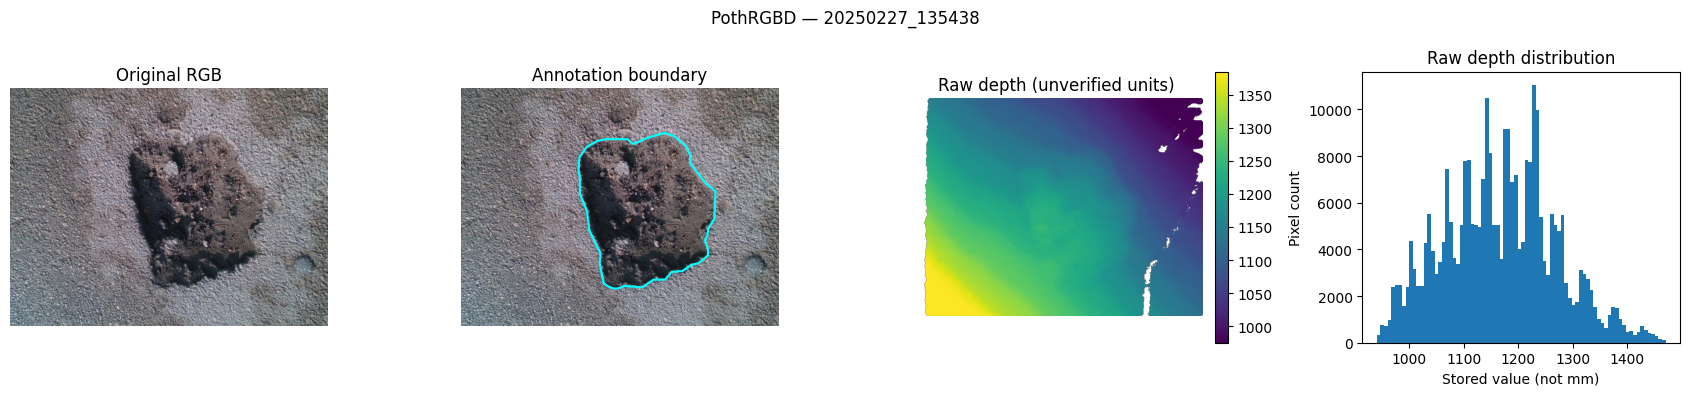

Sample: 20250227_135438
Depth dtype: uint16
Raw median: 1169.0
Zero fraction: 0.059205729166666665
Mask fraction: 0.21330729166666668
Nonzero fraction inside mask: 1.0


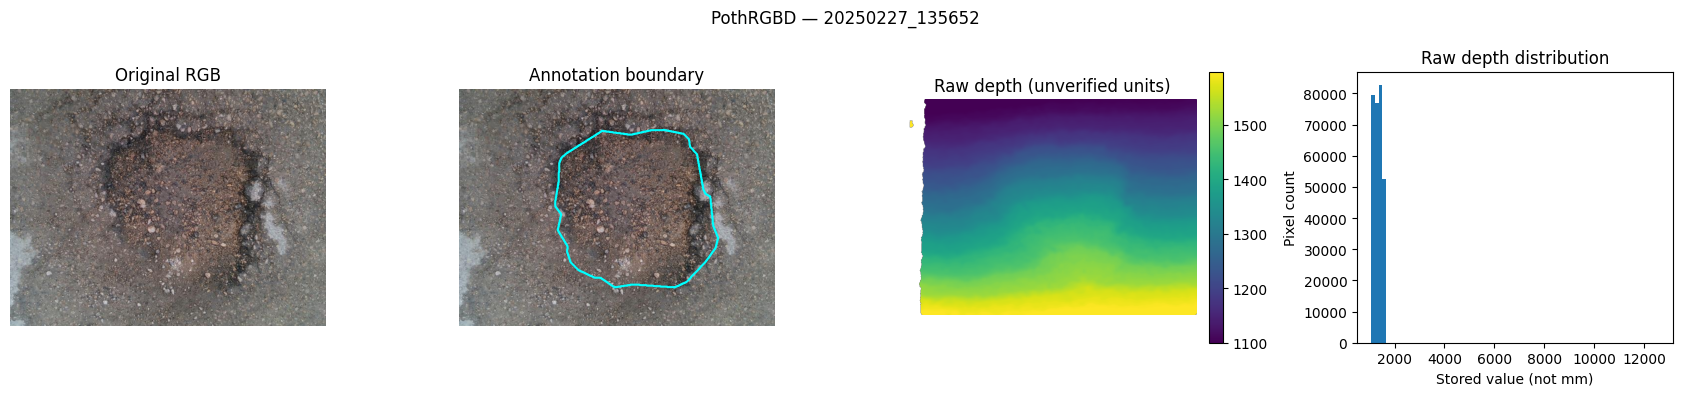

Sample: 20250227_135652
Depth dtype: uint16
Raw median: 1335.0
Zero fraction: 0.04975911458333333
Mask fraction: 0.27781575520833335
Nonzero fraction inside mask: 1.0


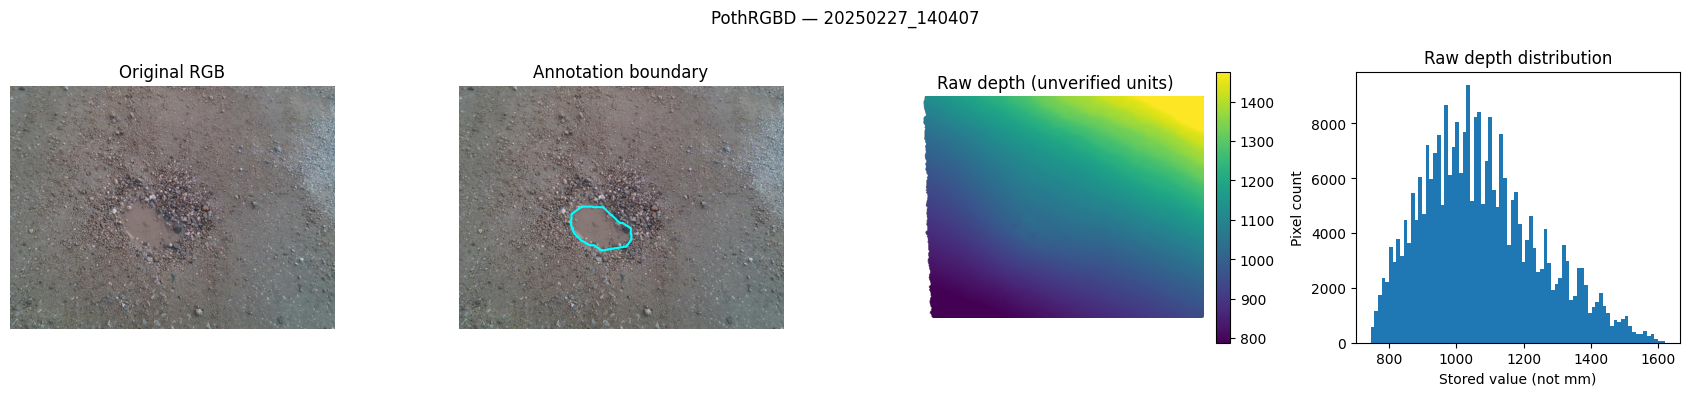

Sample: 20250227_140407
Depth dtype: uint16
Raw median: 1055.0
Zero fraction: 0.06794921875
Mask fraction: 0.023828125
Nonzero fraction inside mask: 1.0

DATASET: Pothole440


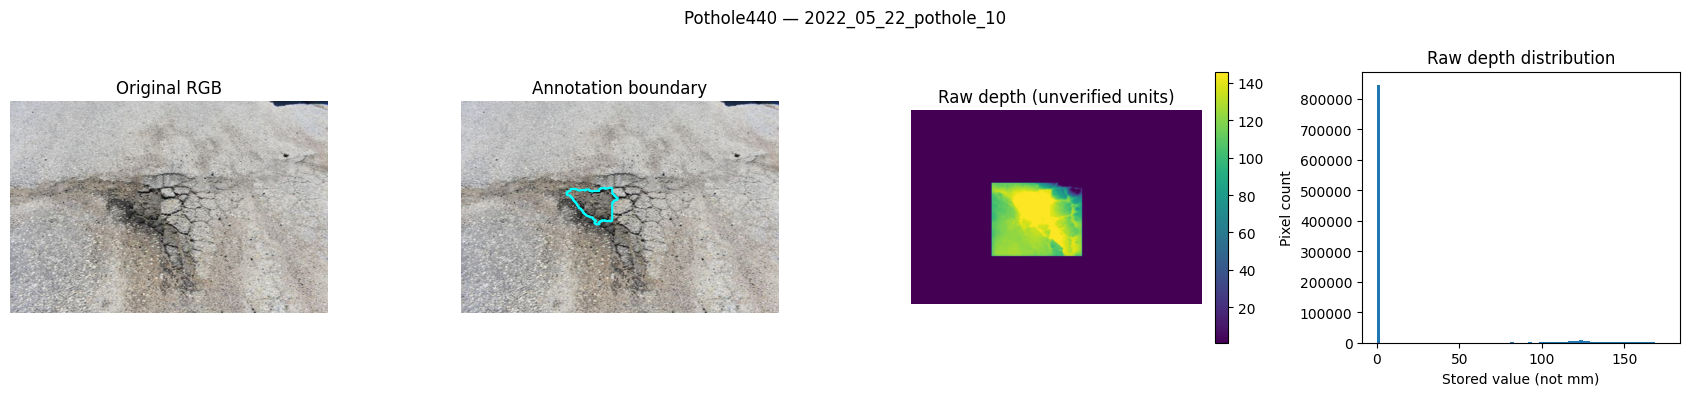

Sample: 2022_05_22_pothole_10
Depth dtype: uint8
Raw median: 1.0
Zero fraction: 0.0028270833333333334
Mask fraction: 0.016322916666666666
Nonzero fraction inside mask: 1.0


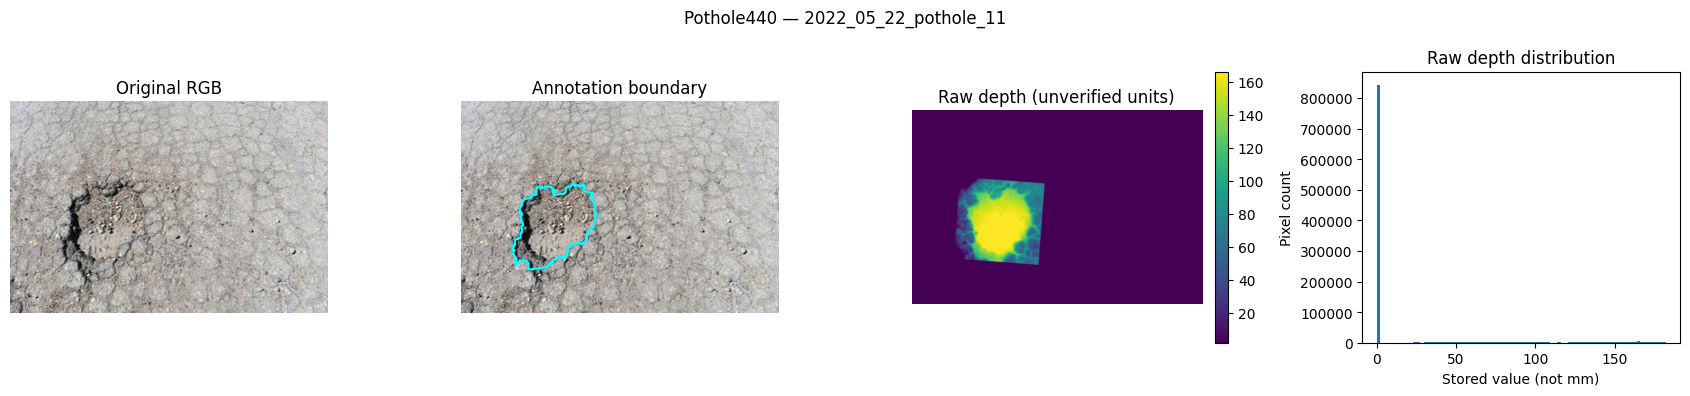

Sample: 2022_05_22_pothole_11
Depth dtype: uint8
Raw median: 2.0
Zero fraction: 0.0010416666666666667
Mask fraction: 0.071384375
Nonzero fraction inside mask: 0.9988326110113966


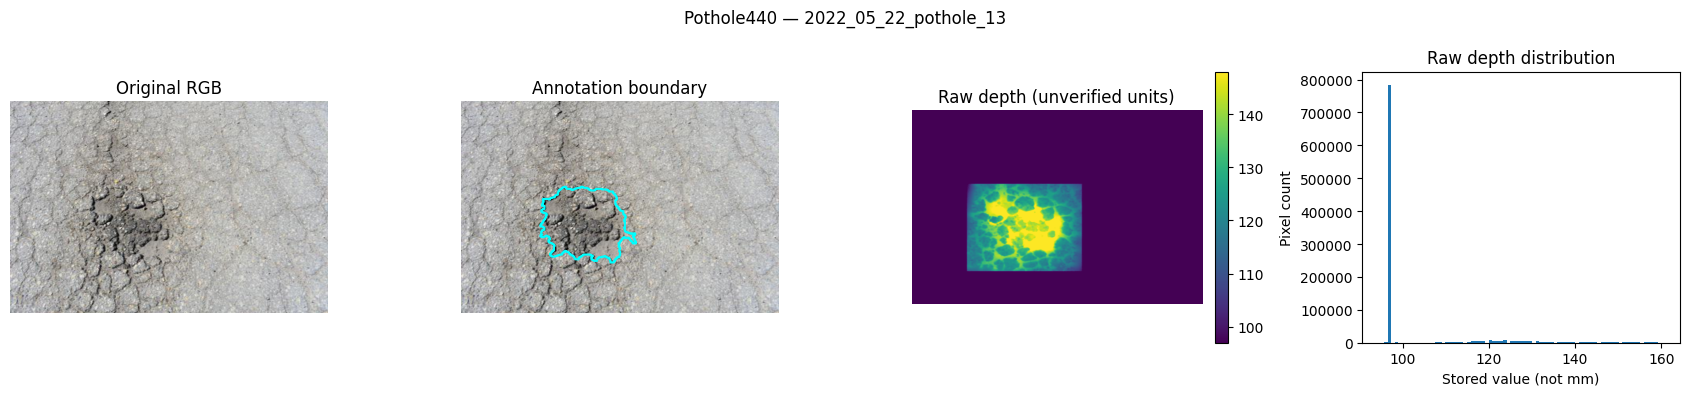

Sample: 2022_05_22_pothole_13
Depth dtype: uint8
Raw median: 97.0
Zero fraction: 0.0
Mask fraction: 0.07441458333333334
Nonzero fraction inside mask: 1.0

C3-00 SECTION 4 — FINISHED
Samples inspected: 6
Probe errors: 0
Saved to: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-00_section04_20261020T030823_151652Z
Metric training authorized: NO


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-00
# SECTION 4: VISUAL ALIGNMENT AND DEPTH QUALITY
# Version: 1.0
# DEVELOPMENT-ONLY | NO METRIC SCALE ASSUMPTIONS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageDraw
import numpy as np
import matplotlib.pyplot as plt
import hashlib
import json

DATA = Path("/content/drive/MyDrive/manushi_research_data")

AUDIT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

RUN_ID = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDIT / f"C3-00_section04_{RUN_ID}"
OUT.mkdir(parents=False, exist_ok=False)

# Explicit development samples only.
# No test or historical held-out directories.
SAMPLES = {
    "PothRGBD": [
        "20250227_135438",
        "20250227_135652",
        "20250227_140407",
    ],
    "Pothole440": [
        "2022_05_22_pothole_10",
        "2022_05_22_pothole_11",
        "2022_05_22_pothole_13",
    ],
}

def unique_match(folder, pattern):
    matches = sorted(folder.glob(pattern))
    if len(matches) != 1:
        raise ValueError(
            f"Expected 1 match, found {len(matches)} "
            f"for {folder / pattern}"
        )
    return matches[0]

# ------------------------------------------------------------
# 1. CONVERT YOLO POLYGON ANNOTATIONS TO BINARY MASK
# ------------------------------------------------------------

def yolo_polygon_mask(label_file, height, width):
    mask_img = Image.new("L", (width, height), 0)
    drawer = ImageDraw.Draw(mask_img)

    polygons_found = 0
    rejected_lines = 0

    for line in label_file.read_text(
        encoding="utf-8"
    ).splitlines():

        tokens = line.strip().split()

        # YOLO segmentation requires a class plus at
        # least three normalized (x, y) pairs.
        if len(tokens) < 7 or len(tokens[1:]) % 2:
            rejected_lines += 1
            continue

        try:
            int(tokens[0])
            coords = np.array(
                [float(x) for x in tokens[1:]],
                dtype=np.float64
            ).reshape(-1, 2)
        except ValueError:
            rejected_lines += 1
            continue

        if (
            not np.isfinite(coords).all()
            or np.any(coords < 0)
            or np.any(coords > 1)
        ):
            rejected_lines += 1
            continue

        points = [
            (
                int(round(x * (width - 1))),
                int(round(y * (height - 1)))
            )
            for x, y in coords
        ]

        drawer.polygon(points, fill=255)
        polygons_found += 1

    return (
        np.asarray(mask_img) > 0,
        polygons_found,
        rejected_lines
    )

# ------------------------------------------------------------
# 2. READ ONLY EXPLICIT SAMPLE FILES
# ------------------------------------------------------------

def load_sample(dataset, key):

    if dataset == "PothRGBD":

        base = DATA / "pothrgbd" / "PData-main"

        rgb_path = unique_match(
            base / "images",
            f"{key}_color_png.rf.*.jpg"
        )

        label_path = unique_match(
            base / "labels",
            f"{key}_color_png.rf.*.txt"
        )

        depth_path = base / "depths" / f"{key}_depth.npy"

        if not depth_path.is_file():
            raise FileNotFoundError(depth_path)

        with Image.open(rgb_path) as img:
            rgb = np.array(img.convert("RGB"))

        depth = np.load(
            depth_path,
            allow_pickle=False
        )

        mask, n_polygons, rejected = yolo_polygon_mask(
            label_path, rgb.shape[0], rgb.shape[1]
        )

        # For the RealSense candidate, zero is treated as
        # a possible invalid depth code, not zero distance.
        valid = np.isfinite(depth) & (depth > 0)

        mask_info = {
            "parsed_polygons": n_polygons,
            "rejected_annotation_lines": rejected,
        }

    elif dataset == "Pothole440":

        base = DATA / "Pothole440-main" / "train"

        rgb_path = base / "rgb" / f"{key}.png"
        depth_path = base / "depth" / f"{key}.png"
        mask_path = base / "mask" / f"{key}.png"

        with Image.open(rgb_path) as img:
            rgb = np.array(img.convert("RGB"))

        with Image.open(depth_path) as img:
            depth = np.array(img)

        with Image.open(mask_path) as img:
            mask = np.array(img.convert("L")) > 0

        # Unknown grayscale encoding:
        # Do not interpret zeros as invalid sensor returns.
        valid = np.isfinite(depth)

        mask_info = {
            "mask_source": "original_png",
            "foreground_convention_unverified": True,
        }

    else:
        raise ValueError("Unexpected dataset")

    if (
        rgb.shape[:2] != depth.shape[:2]
        or depth.shape != mask.shape
        or depth.ndim != 2
    ):
        raise ValueError(
            "RGB/depth/mask dimension mismatch"
        )

    return rgb, depth, mask, valid, mask_info

# ------------------------------------------------------------
# 3. COMPUTE RAW DATA QUALITY STATISTICS
# ------------------------------------------------------------

def raw_depth_stats(depth, mask, valid):

    values = depth[valid].astype(np.float64)

    result = {
        "shape": list(depth.shape),
        "dtype": str(depth.dtype),
        "stored_min": float(np.min(depth)),
        "stored_max": float(np.max(depth)),
        "zero_fraction": float(np.mean(depth == 0)),
        "mask_fraction": float(np.mean(mask)),
        "nonzero_fraction_inside_mask": (
            float(np.mean(depth[mask] != 0))
            if mask.any() else None
        ),
        "nonzero_fraction_outside_mask": (
            float(np.mean(depth[~mask] != 0))
            if (~mask).any() else None
        ),
        "physical_units_verified": False,
    }

    if values.size:
        result.update({
            "raw_median": float(np.median(values)),
            "raw_p02": float(np.percentile(values, 2)),
            "raw_p98": float(np.percentile(values, 98)),
            "raw_p99": float(np.percentile(values, 99)),
        })

    return result

# ------------------------------------------------------------
# 4. CREATE SIDE-BY-SIDE VISUAL DIAGNOSTICS
# ------------------------------------------------------------

reports = []

for dataset, keys in SAMPLES.items():

    print(f"\n{'=' * 55}")
    print("DATASET:", dataset)
    print("=" * 55)

    for key in keys:

        try:
            rgb, depth, mask, valid, mask_info = (
                load_sample(dataset, key)
            )

            stats = raw_depth_stats(depth, mask, valid)

            # Do not create an empty-pothole plot silently.
            if not mask.any():
                raise ValueError(
                    "Annotation mask has no foreground pixels"
                )

            depth_values = depth[valid].astype(float)

            if not depth_values.size:
                raise ValueError(
                    "No depth values available for plotting"
                )

            low, high = np.percentile(
                depth_values, [2, 98]
            )

            if high <= low:
                high = low + 1

            depth_display = np.ma.array(
                depth.astype(float),
                mask=~valid
            )

            fig, ax = plt.subplots(
                1, 4,
                figsize=(17, 4)
            )

            # Original RGB
            ax[0].imshow(rgb)
            ax[0].set_title("Original RGB")

            # RGB with annotation boundary
            ax[1].imshow(rgb)
            ax[1].contour(
                mask.astype(float),
                levels=[0.5],
                colors="cyan",
                linewidths=1.5
            )
            ax[1].set_title("Annotation boundary")

            # Stored depth values, NOT millimetres
            im = ax[2].imshow(
                depth_display,
                cmap="viridis",
                vmin=low,
                vmax=high
            )
            ax[2].set_title("Raw depth (unverified units)")
            fig.colorbar(
                im, ax=ax[2], fraction=0.046, pad=0.04
            )

            # Raw value distribution
            ax[3].hist(
                depth_values,
                bins=80
            )
            ax[3].set_title("Raw depth distribution")
            ax[3].set_xlabel("Stored value (not mm)")
            ax[3].set_ylabel("Pixel count")

            for a in ax[:3]:
                a.axis("off")

            fig.suptitle(
                f"{dataset} — {key}",
                fontsize=12
            )

            fig.tight_layout()

            figure_path = (
                OUT / f"{dataset}_{key}_inspection.png"
            )
            fig.savefig(
                figure_path,
                dpi=125,
                bbox_inches="tight"
            )
            plt.show()
            plt.close(fig)

            print("Sample:", key)
            print("Depth dtype:", stats["dtype"])
            print("Raw median:", stats["raw_median"])
            print("Zero fraction:", stats["zero_fraction"])
            print("Mask fraction:", stats["mask_fraction"])
            print(
                "Nonzero fraction inside mask:",
                stats["nonzero_fraction_inside_mask"]
            )

            reports.append({
                "dataset": dataset,
                "sample": key,
                "status": "VISUAL_INSPECTION_REQUIRED",
                "depth_stats": stats,
                "annotation_diagnostics": mask_info,
                "visualization": figure_path.name,
                "alignment_verified": False,
                "metric_verified": False,
            })

        except Exception as error:

            print("ERROR:", dataset, key, str(error))

            reports.append({
                "dataset": dataset,
                "sample": key,
                "status": "PROBE_ERROR",
                "error": str(error),
            })

# ------------------------------------------------------------
# 5. SAVE AUDIT OUTPUTS AND CHECKSUMS
# ------------------------------------------------------------

report = {
    "milestone": "C3-00",
    "section": 4,
    "version": "1.0",
    "reports": reports,
    "metric_training_authorized": False,
    "alignment_certified": False,
    "protected_test_accessed": False,
    "caution": (
        "Raw depth units must not be interpreted as "
        "physical pothole depth. Visual agreement is "
        "not proof of camera registration."
    ),
}

report_path = OUT / "visual_depth_audit.json"

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

checksums = []

for path in sorted(OUT.iterdir()):

    if path.is_file():
        sha = hashlib.sha256(path.read_bytes()).hexdigest()
        checksums.append(f"{sha}  {path.name}")

(OUT / "checksums.sha256").write_text(
    "\n".join(checksums) + "\n",
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("C3-00 SECTION 4 — FINISHED")
print("=" * 65)
print("Samples inspected:", len(reports))
print("Probe errors:", sum(
    r["status"] == "PROBE_ERROR" for r in reports
))
print("Saved to:", OUT)
print("Metric training authorized: NO")
print("=" * 65)


In [ ]:

# C3-00 — POST-UPLOAD VERIFICATION
# Read-only; does not access protected test sets.

from pathlib import Path
import os

ROOT = Path("/content/drive/MyDrive/manushi_research_data")

folders = {
    "Attain WS V2 Images":
        "Attain/Attain_SMP_WS_V2.0/Images",
    "Attain WS V2 Labels":
        "Attain/Attain_SMP_WS_V2.0/Labels",
    "Pothole440 Train RGB":
        "Pothole440-main/train/rgb",
    "Pothole440 Train Depth":
        "Pothole440-main/train/depth",
    "Pothole440 Train Masks":
        "Pothole440-main/train/mask",
    "SUT-Crack Original Images":
        "SUT-Crack/1-Segmentation/Original Image",
    "SUT-Crack Ground Truth":
        "SUT-Crack/1-Segmentation/Ground Truth"
}

print("=" * 65)
print("C3-00 — POST-UPLOAD VERIFICATION")
print("=" * 65)

for name, relative in folders.items():
    path = ROOT / relative

    if not path.is_dir():
        print(f"MISSING | {name}")
        continue

    with os.scandir(path) as entries:
        count = sum(
            1 for entry in entries
            if entry.is_file(follow_symlinks=False)
        )

    status = "FOUND" if count > 0 else "EMPTY"

    print(f"{status:7} | {name:29} | {count} files")

print("=" * 65)
print("Check completed. File completeness remains to be audited.")


C3-00 — POST-UPLOAD VERIFICATION
FOUND   | Attain WS V2 Images           | 847 files
FOUND   | Attain WS V2 Labels           | 847 files
FOUND   | Pothole440 Train RGB          | 350 files
FOUND   | Pothole440 Train Depth        | 350 files
FOUND   | Pothole440 Train Masks        | 350 files
FOUND   | SUT-Crack Original Images     | 130 files
FOUND   | SUT-Crack Ground Truth        | 130 files
Check completed. File completeness remains to be audited.


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-00
# SECTION 5: DEPTH/MASK SPATIAL SANITY CHECK
# READ-ONLY | NO PHYSICAL DEPTH CLAIMS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from scipy.ndimage import distance_transform_edt
import numpy as np
import matplotlib.pyplot as plt
import hashlib
import json

if "load_sample" not in globals():
    raise RuntimeError(
        "Run Section 4 first to initialize load_sample()."
    )

AUDIT_ROOT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

run_id = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDIT_ROOT / f"C3-00_section05_{run_id}"
OUT.mkdir(exist_ok=False)

SAMPLES = {
    "PothRGBD": [
        "20250227_135438",
        "20250227_135652",
        "20250227_140407",
    ],
    "Pothole440": [
        "2022_05_22_pothole_10",
        "2022_05_22_pothole_11",
        "2022_05_22_pothole_13",
    ],
}

def fit_local_raw_reference(depth, mask, valid):
    """
    Diagnostic plane in image coordinates.
    This is NOT a calibrated physical road plane.
    """

    h, w = depth.shape

    distance = distance_transform_edt(~mask)

    # Nearby pavement support: outside mask,
    # separated by a small guard band.
    ring = (
        (distance >= 8)
        & (distance <= 35)
        & valid
    )

    yy, xx = np.where(ring)

    if len(xx) < 200:
        raise ValueError(
            "Insufficient valid surrounding pavement"
        )

    raw = depth[yy, xx].astype(np.float64)

    X = np.column_stack([
        np.ones(len(xx)),
        xx / w,
        yy / h,
    ])

    # Deterministic robust fitting:
    # avoid large isolated raw-depth outliers.
    lo, hi = np.percentile(raw, [1, 99])
    keep = (raw >= lo) & (raw <= hi)

    if keep.sum() < 200:
        raise ValueError("Insufficient robust support")

    for _ in range(4):
        beta = np.linalg.lstsq(
            X[keep],
            raw[keep],
            rcond=None
        )[0]

        errors = raw - X @ beta
        center = np.median(errors[keep])

        mad = np.median(
            np.abs(errors[keep] - center)
        )

        sigma = max(1.4826 * mad, 1.0)

        new_keep = (
            (np.abs(errors - center) <= 3.5 * sigma)
            & (raw >= lo)
            & (raw <= hi)
        )

        if new_keep.sum() < 200:
            break

        keep = new_keep

    beta = np.linalg.lstsq(
        X[keep],
        raw[keep],
        rcond=None
    )[0]

    Y, Xgrid = np.indices(depth.shape)

    reference = (
        beta[0]
        + beta[1] * (Xgrid / w)
        + beta[2] * (Y / h)
    )

    residual = depth.astype(float) - reference

    return reference, residual, ring, int(keep.sum())


results = []

for dataset, keys in SAMPLES.items():

    print(f"\nDATASET: {dataset}")

    for key in keys:

        try:
            rgb, depth, mask, valid, info = (
                load_sample(dataset, key)
            )

            reference, residual, ring, support_n = (
                fit_local_raw_reference(
                    depth, mask, valid
                )
            )

            y_pixels, x_pixels = np.where(mask)

            if not len(x_pixels):
                raise ValueError("Empty damage mask")

            # Crop around the actual damage.
            margin = 55
            h, w = depth.shape

            x0 = max(0, x_pixels.min() - margin)
            x1 = min(w, x_pixels.max() + margin + 1)
            y0 = max(0, y_pixels.min() - margin)
            y1 = min(h, y_pixels.max() + margin + 1)

            raw_valid = depth[valid].astype(float)

            vmin, vmax = np.percentile(
                raw_valid, [2, 98]
            )

            if vmax <= vmin:
                vmax = vmin + 1

            cropped_res = residual[y0:y1, x0:x1]
            cropped_mask = mask[y0:y1, x0:x1]

            display_scale = max(
                float(np.percentile(
                    np.abs(cropped_res), 95
                )),
                1.0
            )

            # Choose a horizontal row crossing
            # the most annotated pixels.
            row_idx = int(np.argmax(mask.sum(axis=1)))
            xp = np.arange(x0, x1)
            selected = mask[row_idx, x0:x1]

            fig, axes = plt.subplots(
                1, 4, figsize=(18, 4)
            )

            axes[0].imshow(rgb)
            axes[0].contour(
                mask.astype(float),
                levels=[0.5],
                colors="cyan"
            )
            axes[0].set_title("RGB + damage mask")
            axes[0].axis("off")

            axes[1].imshow(
                depth, cmap="viridis",
                vmin=vmin, vmax=vmax
            )
            axes[1].contour(
                mask.astype(float),
                levels=[0.5],
                colors="red",
                linewidths=1.5
            )
            axes[1].set_title("Depth + same mask")
            axes[1].axis("off")

            axes[2].imshow(
                cropped_res,
                cmap="coolwarm",
                vmin=-display_scale,
                vmax=display_scale
            )
            axes[2].contour(
                cropped_mask.astype(float),
                levels=[0.5],
                colors="black"
            )
            axes[2].set_title(
                "Local raw residual (not metres)"
            )
            axes[2].axis("off")

            axes[3].plot(
                xp,
                depth[row_idx, x0:x1],
                label="Raw depth"
            )
            axes[3].plot(
                xp,
                reference[row_idx, x0:x1],
                label="Local fitted reference"
            )

            axes[3].scatter(
                xp[selected],
                depth[row_idx, x0:x1][selected],
                s=5,
                label="Annotated pixels"
            )

            axes[3].set_title("Raw depth profile")
            axes[3].set_xlabel("Pixel column")
            axes[3].set_ylabel("Stored units")
            axes[3].legend(fontsize=7)

            fig.suptitle(f"{dataset} | {key}")
            fig.tight_layout()

            image_path = OUT / (
                f"{dataset}_{key}_spatial_check.png"
            )

            fig.savefig(
                image_path, dpi=130,
                bbox_inches="tight"
            )
            plt.show()
            plt.close(fig)

            inner = mask & valid

            result = {
                "dataset": dataset,
                "sample": key,
                "status": "DIAGNOSTIC_ONLY",
                "mask_valid_fraction": float(
                    valid[mask].mean()
                ),
                "support_pixels_used": support_n,
                "median_raw_residual_in_mask": float(
                    np.median(residual[inner])
                ) if inner.any() else None,
                "median_raw_residual_in_ring": float(
                    np.median(residual[ring])
                ),
                "raw_units_only": True,
                "metric_verified": False,
                "registration_verified": False,
                "figure": image_path.name,
            }

            results.append(result)

            print(
                key,
                "| support:", support_n,
                "| median raw residual:",
                result["median_raw_residual_in_mask"]
            )

        except Exception as exc:
            print("ERROR:", key, str(exc))
            results.append({
                "dataset": dataset,
                "sample": key,
                "status": "PROBE_ERROR",
                "error": str(exc),
            })

# Save the audit.
report = {
    "milestone": "C3-00",
    "section": 5,
    "method": "local_image_coordinate_plane_diagnostic",
    "results": results,
    "physical_depth_verified": False,
    "training_authorized": False,
    "warning": (
        "The fitted reference is in raw image coordinates. "
        "Residuals are neither measured depression nor "
        "physically calibrated geometry."
    ),
}

report_file = OUT / "spatial_sanity_report.json"

report_file.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

hashes = []

for file in sorted(OUT.iterdir()):
    if file.is_file():
        digest = hashlib.sha256(
            file.read_bytes()
        ).hexdigest()
        hashes.append(
            f"{digest}  {file.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(hashes) + "\n",
    encoding="utf-8"
)

print("\nC3-00 SECTION 5 COMPLETE")
print("Samples:", len(results))
print(
    "Errors:",
    sum(r["status"] == "PROBE_ERROR" for r in results)
)
print("Output:", OUT)
print("Metric training authorized: NO")


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-00
# SECTION 6: DATASET PROVENANCE & CALIBRATION EVIDENCE
# READ-ONLY | NO EXTRACTION | NO MODEL TRAINING
# ============================================================

from pathlib import Path, PurePosixPath
from collections import Counter
from datetime import datetime, timezone
import csv
import hashlib
import json
import re
import zipfile

# ------------------------------------------------------------
# 1. DEFINE PATHS
# ------------------------------------------------------------

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data"
)

AUDITS = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

assert DATA.is_dir() and AUDITS.is_dir(), (
    "Mount Google Drive and verify paths first."
)

STAMP = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDITS / f"C3-00_section06_{STAMP}"
OUT.mkdir(exist_ok=False)

# ------------------------------------------------------------
# 2. REGISTER DOCUMENTATION AND CALIBRATION CANDIDATES
# ------------------------------------------------------------

READMES = {
    "Pothole440":
        "Pothole440-main/README.md",

    "Fan stereo":
        "fan_stereo_pothole/"
        "stereo_pothole_datasets-master/README.md",

    "Fan road surface":
        "fan_road_surface/"
        "road_surface_3d_reconstruction_datasets-master/"
        "README.md",
}

MAT_CANDIDATES = {
    "Fan road calibration":
        "fan_road_surface/"
        "road_surface_3d_reconstruction_datasets-master/"
        "dataset 1/stereoParams.mat",

    "Fan stereo disparity":
        "fan_stereo_pothole/"
        "stereo_pothole_datasets-master/"
        "dataset1/disp/01.mat",

    "Fan stereo point cloud":
        "fan_stereo_pothole/"
        "stereo_pothole_datasets-master/"
        "dataset1/ptcloud/01.mat",
}

ARCHIVES = {
    "SHREC Pothole-Mix":
        "shrec2022/kfth5g2xk3-2/"
        "Pothole-Mix/pothole-mix-v1.0-20220526.zip",

    "SHREC RGB-D videos":
        "shrec2022/kfth5g2xk3-2/"
        "RGB-D/shrec-2022-potholes-rgbd-videos.zip",

    "SHREC RGB-D masks":
        "shrec2022/kfth5g2xk3-2/"
        "RGB-D/shrec-2022-potholes-rgbd-videos-masks.zip",
}

KEYWORDS = re.compile(
    r"depth|scale|units?|calibra|sensor|scanner|"
    r"stereo|disparity|baseline|metric|millimet|"
    r"intrinsic|extrinsic|ground.truth|licen[cs]",
    re.I
)

# ------------------------------------------------------------
# 3. READ-ONLY SAFETY HELPER
# ------------------------------------------------------------

def located(relative):
    p = DATA / relative

    if (
        ".." in Path(relative).parts
        or not p.resolve().is_relative_to(DATA.resolve())
    ):
        raise ValueError("Unsafe source path")

    return p

# ------------------------------------------------------------
# 4. INSPECT AUTHOR DOCUMENTATION
# ------------------------------------------------------------

def inspect_text(relative):
    p = located(relative)

    if not p.is_file() or p.is_symlink():
        return {"status": "NOT_FOUND"}

    if p.stat().st_size > 128_000:
        return {"status": "SKIPPED_OVERSIZE"}

    lines = p.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    selected = [
        {
            "line": i,
            "excerpt": line.strip()[:240]
        }
        for i, line in enumerate(lines, 1)
        if KEYWORDS.search(line)
    ]

    return {
        "status": "READ",
        "bytes": p.stat().st_size,
        "relevant_lines_first_15": selected[:15],
        "matching_lines_total": len(selected),
        "unit_certified": False,
    }

# ------------------------------------------------------------
# 5. INSPECT MATLAB FILE HEADERS
# ------------------------------------------------------------

def inspect_mat(relative):
    p = located(relative)

    if not p.is_file() or p.is_symlink():
        return {"status": "NOT_FOUND"}

    try:
        from scipy.io import whosmat

        items = whosmat(str(p))

        return {
            "status": "VARIABLE_HEADERS_READ",
            "variables": [
                {
                    "name": name,
                    "shape": list(shape),
                    "class": typ
                }
                for name, shape, typ in items[:25]
            ],
            "unit_certified": False,
        }

    except Exception as exc:
        return {
            "status": "MAT_HEADER_UNREADABLE",
            "reason": (
                f"{type(exc).__name__}: "
                f"{str(exc)[:200]}"
            ),
            "unit_certified": False,
        }

# ------------------------------------------------------------
# 6. DEFINE PROTECTED ZIP MEMBER POLICY
# ------------------------------------------------------------

def protected_zip_name(name):
    segments = [
        re.sub(r"[^a-z0-9]", "", x.lower())
        for x in PurePosixPath(name).parts
    ]

    return any(
        x in {
            "test", "testing", "holdout",
            "heldout", "benchmark", "dataset2"
        }
        or x.startswith("testset")
        for x in segments
    )

# ------------------------------------------------------------
# 7. INSPECT ZIP CENTRAL DIRECTORIES ONLY
# ------------------------------------------------------------

def inspect_zip_index(relative):
    p = located(relative)

    if not p.is_file() or p.is_symlink():
        return {"status": "NOT_FOUND"}

    result = {
        "status": None,
        "archive_bytes": p.stat().st_size,
        "archive_sha256_verified": False,
        "contents_extracted": False,
        "member_payloads_read": False,
    }

    try:
        # Reads archive directory metadata only.
        # No images or videos are decompressed.
        with zipfile.ZipFile(p, mode="r") as z:

            infos = z.infolist()

            usable = [
                x for x in infos
                if not x.is_dir()
                and not protected_zip_name(x.filename)
            ]

            extensions = Counter(
                PurePosixPath(x.filename).suffix.lower()
                or "[none]"
                for x in usable
            )

            videos = sum(
                x.filename.lower().endswith(
                    (".mp4", ".avi", ".mkv", ".mov")
                )
                for x in usable
            )

            nested_zips = sum(
                x.filename.lower().endswith(".zip")
                for x in usable
            )

            blocked = sum(
                not x.is_dir()
                and protected_zip_name(x.filename)
                for x in infos
            )

            result.update({
                "status": "CENTRAL_DIRECTORY_READ",
                "total_zip_entries_including_directories":
                    len(infos),
                "nonprotected_file_entries": len(usable),
                "protected_member_names_omitted":
                    blocked,
                "extensions_nonprotected":
                    dict(extensions.most_common(15)),
                "video_member_count": videos,
                "nested_zip_member_count": nested_zips,
                "warning": (
                    "ZIP directory readability does not "
                    "verify complete archive integrity."
                ),
            })

    except Exception as exc:
        result.update({
            "status": "ZIP_INDEX_NOT_READABLE",
            "reason": (
                f"{type(exc).__name__}: "
                f"{str(exc)[:200]}"
            ),
        })

    return result

# ------------------------------------------------------------
# 8. EXECUTE PROVENANCE AUDIT
# ------------------------------------------------------------

readme_results = {
    name: inspect_text(path)
    for name, path in READMES.items()
}

mat_results = {
    name: inspect_mat(path)
    for name, path in MAT_CANDIDATES.items()
}

zip_results = {}

for name, relative in ARCHIVES.items():

    print(
        f"Checking ZIP metadata: {name} "
        "(no extraction)...",
        flush=True
    )

    zip_results[name] = inspect_zip_index(relative)

    print(
        "  status:",
        zip_results[name]["status"],
        flush=True
    )

# ------------------------------------------------------------
# 9. SAVE SCIENTIFIC EVIDENCE
# ------------------------------------------------------------

report = {
    "milestone": "C3-00",
    "section": 6,
    "created_utc": STAMP,
    "method":
        "READ_ONLY_DOCUMENTATION_MAT_HEADERS_ZIP_INDEX",
    "documentation": readme_results,
    "fan_development_only_mat_metadata": mat_results,
    "shrec_zip_indexes": zip_results,

    "pothrgbd_scale_status":
        "UNVERIFIED_SENSOR_DEPTH_UNITS",

    "pothole440_scale_status":
        "UNVERIFIED_GRAYSCALE_ENCODING",

    "butt_scale_status":
        "UNVERIFIED_DEPTH_PNG_ENCODING",

    "protected_fan_dataset2_accessed": False,
    "frozen_399_benchmark_accessed": False,

    "metric_label_generation_authorized": False,
    "model_training_authorized": False,
}

json_file = OUT / "source_calibration_evidence.json"

json_file.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

csv_file = OUT / "shrec_zip_summary.csv"

with csv_file.open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "archive",
        "status",
        "archive_bytes",
        "nonprotected_entries",
        "video_entries",
        "nested_zip_entries",
    ])

    for name, d in zip_results.items():
        writer.writerow([
            name,
            d.get("status"),
            d.get("archive_bytes"),
            d.get("nonprotected_file_entries"),
            d.get("video_member_count"),
            d.get("nested_zip_member_count"),
        ])

# ------------------------------------------------------------
# 10. SAVE SHA256 CHECKSUMS OF GENERATED REPORTS
# ------------------------------------------------------------

checksum_file = OUT / "checksums.sha256"

with checksum_file.open(
    "w", encoding="utf-8"
) as f:

    for path in sorted(OUT.iterdir()):

        if path.name == "checksums.sha256":
            continue

        digest = hashlib.sha256(
            path.read_bytes()
        ).hexdigest()

        f.write(f"{digest}  {path.name}\n")

# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-00 SECTION 6 SUMMARY")
print("=" * 65)

for name, d in readme_results.items():
    print(
        "DOC |", name,
        "|", d["status"],
        "| relevant lines:",
        d.get("matching_lines_total", 0)
    )

for name, d in mat_results.items():
    variables = [
        v["name"]
        for v in d.get("variables", [])
    ]

    print(
        "MAT |", name,
        "|", d["status"],
        "| variables:", variables
    )

for name, d in zip_results.items():
    print(
        "ZIP |", name,
        "|", d["status"],
        "| eligible entries:",
        d.get("nonprotected_file_entries", "?")
    )

print("\nSaved reports:", OUT)
print("Metric label generation authorized: NO")
print("Model training authorized: NO")
print("=" * 65)


Checking ZIP metadata: SHREC Pothole-Mix (no extraction)...
  status: CENTRAL_DIRECTORY_READ
Checking ZIP metadata: SHREC RGB-D videos (no extraction)...
  status: CENTRAL_DIRECTORY_READ
Checking ZIP metadata: SHREC RGB-D masks (no extraction)...
  status: CENTRAL_DIRECTORY_READ

C3-00 SECTION 6 SUMMARY
DOC | Pothole440 | READ | relevant lines: 12
DOC | Fan stereo | READ | relevant lines: 6
DOC | Fan road surface | READ | relevant lines: 2
MAT | Fan road calibration | MAT_HEADER_UNREADABLE | variables: []
MAT | Fan stereo disparity | VARIABLE_HEADERS_READ | variables: ['disp']
MAT | Fan stereo point cloud | VARIABLE_HEADERS_READ | variables: ['xyzPoints']
ZIP | SHREC Pothole-Mix | CENTRAL_DIRECTORY_READ | eligible entries: 7673
ZIP | SHREC RGB-D videos | CENTRAL_DIRECTORY_READ | eligible entries: 1596
ZIP | SHREC RGB-D masks | CENTRAL_DIRECTORY_READ | eligible entries: 359

Saved reports: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-00_section06_2026

In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-00
# SECTION 7: CALIBRATION EVIDENCE & READINESS GATE
# Version 1.0 | READ-ONLY SOURCE DATA
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from scipy.io import loadmat
import hashlib
import json
import csv

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data"
)

AUDIT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

# ------------------------------------------------------------
# 1. VERIFY OUR PREVIOUS SECTION 6 EVIDENCE
# ------------------------------------------------------------

runs = sorted(AUDIT.glob("C3-00_section06_*"))

if not runs:
    raise FileNotFoundError(
        "Section 6 report missing. Run Section 6 first."
    )

SOURCE_RUN = runs[-1]

evidence_path = (
    SOURCE_RUN / "source_calibration_evidence.json"
)

checksums_path = SOURCE_RUN / "checksums.sha256"

assert evidence_path.is_file()
assert checksums_path.is_file()

# Validate all hashes recorded in Section 6.
verified_files = []

for line in checksums_path.read_text().splitlines():
    if not line.strip():
        continue

    expected_hash, filename = line.split(
        None, 1
    )
    filename = filename.strip()

    if Path(filename).name != filename:
        raise ValueError("Unsafe checksum filename")

    source_file = SOURCE_RUN / filename

    actual_hash = hashlib.sha256(
        source_file.read_bytes()
    ).hexdigest()

    if actual_hash != expected_hash:
        raise RuntimeError(
            f"Checksum mismatch: {filename}"
        )

    verified_files.append(filename)

evidence = json.loads(
    evidence_path.read_text(encoding="utf-8")
)

# All three archives must have readable indexes.
zip_results = evidence["shrec_zip_indexes"]

if len(zip_results) != 3:
    raise RuntimeError("Incomplete SHREC archive list")

if not all(
    v["status"] == "CENTRAL_DIRECTORY_READ"
    for v in zip_results.values()
):
    raise RuntimeError(
        "One or more SHREC ZIP indexes failed"
    )

print("Section 6 report integrity: PASS")
print("Verified files:", verified_files)

# ------------------------------------------------------------
# 2. TRIAGE THE FAN STEREO CALIBRATION OBJECT
# ------------------------------------------------------------

CAL_FILE = (
    DATA / "fan_road_surface"
    / "road_surface_3d_reconstruction_datasets-master"
    / "dataset 1"
    / "stereoParams.mat"
)

assert CAL_FILE.is_file()
assert CAL_FILE.stat().st_size < 5_000_000

mat_report = {
    "path": str(CAL_FILE.relative_to(DATA)),
    "size_bytes": CAL_FILE.stat().st_size,
    "sha256": hashlib.sha256(
        CAL_FILE.read_bytes()
    ).hexdigest(),
    "numeric_calibration_verified": False,
}

with CAL_FILE.open("rb") as f:
    header = f.read(128)

mat_report["matlab_header"] = header.decode(
    "ascii", errors="replace"
)[:116].strip()

try:
    variables = loadmat(
        str(CAL_FILE),
        struct_as_record=False,
        squeeze_me=True
    )

    findings = []

    for name, value in variables.items():

        if name.startswith("__"):
            continue

        entry = {
            "scipy_variable_name": name,
            "python_type": type(value).__name__,
            "shape": list(
                getattr(value, "shape", ())
            ),
        }

        # Detect MATLAB opaque objects without
        # assuming their numeric fields are decoded.
        if type(value).__name__ == "MatlabOpaque":

            records = value.reshape(-1)

            if len(records):
                record = records[0]

                fields = record.dtype.names or ()

                if "s0" in fields:
                    entry["matlab_object_name"] = str(
                        record["s0"]
                    )

                if "s2" in fields:
                    entry["matlab_class"] = str(
                        record["s2"]
                    )

                entry["requires_specialized_extraction"] = True

        findings.append(entry)

    mat_report["status"] = "LOADABLE_WITH_PYTHON"
    mat_report["variables"] = findings

except Exception as exc:
    mat_report["status"] = "PYTHON_LOAD_FAILED"
    mat_report["error"] = (
        type(exc).__name__ + ": " + str(exc)
    )

print("\nFAN CALIBRATION FILE")
print("File:", CAL_FILE.name)
print("Status:", mat_report["status"])

for variable in mat_report.get("variables", []):
    print(variable)

# ------------------------------------------------------------
# 3. PREPARE SCIENTIFIC DATASET READINESS MATRIX
# ------------------------------------------------------------

# The following statuses are conservative research
# decisions, not newly verified physical measurements.

readiness = [
    (
        "PothRGBD",
        "METRIC_CANDIDATE",
        "RealSense depth scale, intrinsics and registration"
    ),
    (
        "Pothole440",
        "ENCODING_UNVERIFIED",
        "Scanner depth PNG physical-value conversion"
    ),
    (
        "Fan stereo dataset1/3",
        "3D_CANDIDATE",
        "Point-cloud units and reference coordinate system"
    ),
    (
        "Fan road surface",
        "CALIBRATION_EXTRACTION_PENDING",
        "MATLAB stereoParameters numeric extraction"
    ),
    (
        "SHREC 2022",
        "DISPARITY_CALIBRATION_PENDING",
        "Video pairing, disparity encoding and stereo calibration"
    ),
    (
        "Butt RGB-LiDAR",
        "ENCODING_UNVERIFIED",
        "Depth PNG encoding and LiDAR metric scale"
    ),
    (
        "Pothole600",
        "TRANSFORMED_DISPARITY",
        "Original metric geometry or valid conversion"
    ),
    (
        "Attain",
        "VISUAL_SEVERITY_SOURCE",
        "Annotation semantics and image-label pairing"
    ),
    (
        "SUT-Crack",
        "CRACK_MORPHOLOGY_SOURCE",
        "Reliable physical image scale for length/width"
    ),
]

# ------------------------------------------------------------
# 4. SAVE VERSIONED READINESS REPORTS
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDIT / f"C3-00_section07_{stamp}"
OUT.mkdir(exist_ok=False)

report = {
    "milestone": "C3-00",
    "section": 7,
    "version": "1.0",
    "source_section06": SOURCE_RUN.name,
    "section06_integrity": "PASS",
    "fan_calibration": mat_report,
    "readiness": [
        {
            "dataset": name,
            "status": status,
            "required_evidence": requirement,
            "metric_certified": False
        }
        for name, status, requirement in readiness
    ],
    "protected_evaluation_reopened": False,
    "metric_label_generation_authorized": False,
    "physical_depth_training_authorized": False,
    "next_milestone": "C3-01_Metric_Calibration",
}

json_path = OUT / "readiness_report.json"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

csv_path = OUT / "dataset_readiness.csv"

with csv_path.open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "dataset",
        "readiness_status",
        "missing_evidence",
        "metric_certified"
    ])

    for name, status, requirement in readiness:
        writer.writerow([
            name, status, requirement, False
        ])

# ------------------------------------------------------------
# 5. CHECKSUM THE GENERATED REPORTS
# ------------------------------------------------------------

checksum_path = OUT / "checksums.sha256"

lines = []

for path in [json_path, csv_path]:
    digest = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()
    lines.append(f"{digest}  {path.name}")

checksum_path.write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 6. FINAL READINESS SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CRDL C3-00 — SECTION 7 READINESS GATE")
print("=" * 65)

for name, status, requirement in readiness:
    print(f"{name:25} | {status}")

print("\nSource evidence integrity: PASS")
print("Calibration evidence: INCOMPLETE")
print("Metric model training: NOT AUTHORIZED")
print("Next milestone: C3-01 Metric Calibration")
print("\nReport location:", OUT)

print("=" * 65)


Section 6 report integrity: PASS
Verified files: ['shrec_zip_summary.csv', 'source_calibration_evidence.json']

FAN CALIBRATION FILE
File: stereoParams.mat
Status: LOADABLE_WITH_PYTHON
{'scipy_variable_name': 'None', 'python_type': 'MatlabOpaque', 'shape': [1], 'matlab_object_name': "b'stereoParams'", 'matlab_class': "b'stereoParameters'", 'requires_specialized_extraction': True}

CRDL C3-00 — SECTION 7 READINESS GATE
PothRGBD                  | METRIC_CANDIDATE
Pothole440                | ENCODING_UNVERIFIED
Fan stereo dataset1/3     | 3D_CANDIDATE
Fan road surface          | CALIBRATION_EXTRACTION_PENDING
SHREC 2022                | DISPARITY_CALIBRATION_PENDING
Butt RGB-LiDAR            | ENCODING_UNVERIFIED
Pothole600                | TRANSFORMED_DISPARITY
Attain                    | VISUAL_SEVERITY_SOURCE
SUT-Crack                 | CRACK_MORPHOLOGY_SOURCE

Source evidence integrity: PASS
Calibration evidence: INCOMPLETE
Metric model training: NOT AUTHORIZED
Next milestone: C3-01 